<a href="https://colab.research.google.com/github/gliao6578/super_mariners/blob/main/maritime_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### End-to-End AIS Shipping Traffic Anomaly Detection
This consolidated cell allows you to upload your local CSV file, dynamically detect the uploaded dataset, apply an `IsolationForest` anomaly detection algorithm, and visualize normal versus anomalous vessel trajectories in one step.

If you wish to upload a new dataset from your computer, run this cell and use the button below.
Otherwise, cancel or leave it empty to use the latest existing file in the directory.



Saving copyAIS_179155869919477421_599-1791558699807.csv to copyAIS_179155869919477421_599-1791558699807 (1).csv
Successfully uploaded file "copyAIS_179155869919477421_599-1791558699807 (1).csv" with length 93430668 bytes

No specific 'ais_shipping_traffic' CSV found. Selected alternative CSV file: ./copyAIS_179155869919477421_599-1791558699807 (1).csv

### Dataset Summary ###
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1013860 entries, 0 to 1013859
Data columns (total 17 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   MMSI              1013860 non-null  int64  
 1   BaseDateTime      1013860 non-null  object 
 2   LAT               1013860 non-null  float64
 3   LON               1013860 non-null  float64
 4   SOG               1013860 non-null  float64
 5   COG               1013860 non-null  float64
 6   Heading           1013860 non-null  int64  
 7   VesselName        1013167 non-null  object 
 8   IMO          

,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass
0,368362480,2024-08-15T22:05:13,32.71936,-117.20887,3.4,113.1,511,NOMAD,NaN,WDP5333,36.0,NaN,3.0,0.0,NaN,NaN,B
1,338497836,2024-08-16T23:43:43,32.72182,-117.20907,3.8,77.5,511,PEARL,NaN,NaN,37.0,NaN,12.0,5.0,NaN,NaN,B
2,368073330,2024-08-17T00:11:01,32.71764,-117.20905,6.0,150.7,511,MAKANI,NaN,WDK6313,36.0,NaN,12.0,0.0,NaN,NaN,B
3,368334330,2024-08-17T00:34:11,32.72280,-117.20921,3.3,274.8,511,BIJOU,NaN,NaN,36.0,NaN,10.0,4.0,NaN,NaN,B
4,368073330,2024-08-17T00:50:01,32.72411,-117.20927,2.7,174.5,511,MAKANI,NaN,WDK6313,36.0,NaN,12.0,0.0,NaN,NaN,B



Using features for anomaly detection: ['LAT', 'LON', 'SOG', 'COG']
Detected 20278 anomalies out of 1013860 records.

Total unique anomalous vessels: 146
Top anomalous vessels by record count:


,count
VesselName,
CACHALOT,1626
OCEAN SPIRIT II,927
JOHN PAUL JONES,923
REELENTLESS,822
ROBYN J,759
JANET LOU,680
BELLA SIGNORA,632
CORINTHIAN,484
OCEANUS,458



Detailed view of the detected anomalies:


,MMSI,VesselName,BaseDateTime,LAT,LON,SOG,COG
9927,338405303,KNOT FOR SAIL,2024-08-18T06:33:31,32.72586,-117.19029,102.3,360.0
458246,338518143,NaN,2024-09-19T19:05:10,32.71365,-117.23018,102.3,254.5
80092,338441159,MAHANA,2024-08-24T18:48:04,32.68185,-117.17338,102.3,0.0
80087,338441159,MAHANA,2024-08-24T18:03:51,32.68192,-117.17333,102.3,256.5
577004,368302540,KAHALA,2024-09-28T02:42:26,32.69262,-117.23232,102.3,197.0
80093,338441159,MAHANA,2024-08-24T18:57:05,32.68188,-117.17340,102.3,0.0
80101,338441159,MAHANA,2024-08-24T19:39:11,32.68190,-117.17337,102.3,261.8
80098,338441159,MAHANA,2024-08-24T19:21:09,32.68192,-117.17338,102.3,0.0
80095,338441159,MAHANA,2024-08-24T19:09:08,32.68193,-117.17340,102.3,0.0
80118,338441159,MAHANA,2024-08-24T23:09:19,32.68188,-117.17335,102.3,0.0


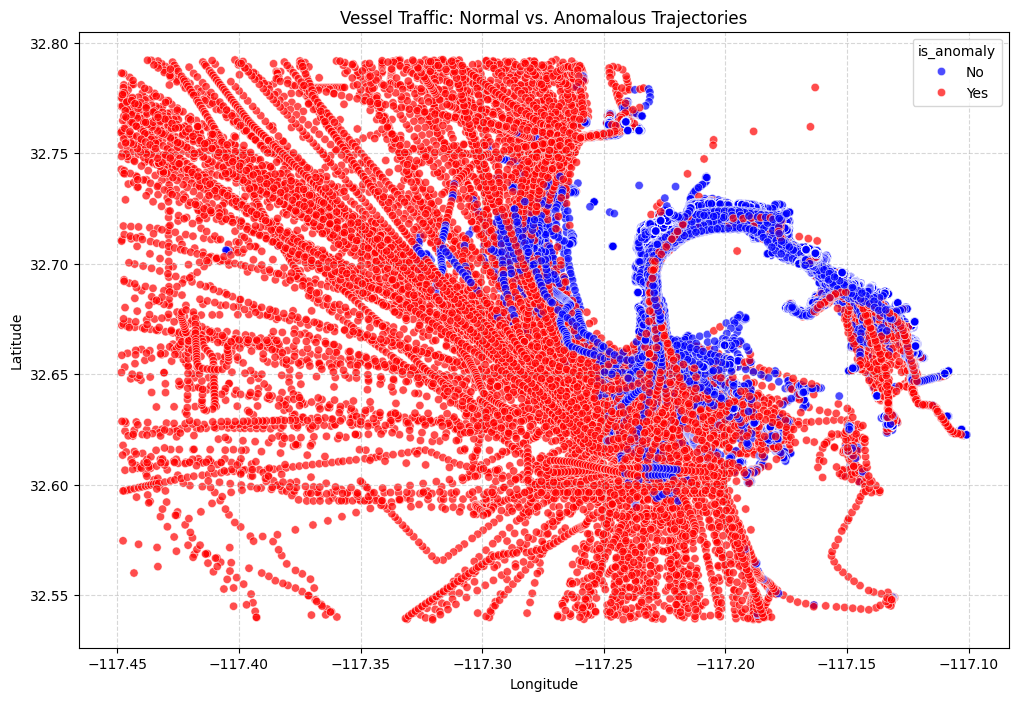

In [3]:
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# --- Step 1: Optional File Upload ---
print("If you wish to upload a new dataset from your computer, run this cell and use the button below.")
print("Otherwise, cancel or leave it empty to use the latest existing file in the directory.\n")

try:
    uploaded = files.upload()
    for fn in uploaded.keys():
        print(f'Successfully uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
except Exception as e:
    print("No new file uploaded. Searching for existing local CSV files...")

# --- Step 2: Automatically Locate and Load the Dataset ---
candidate_files = [f for f in os.listdir('.') if f.startswith('ais_shipping_traffic') and f.endswith('.csv')]

if candidate_files:
    candidate_files.sort(key=os.path.getmtime, reverse=True)
    file_path = os.path.join('.', candidate_files[0])
    print(f"\nSelected dataset file (matching pattern): {file_path}\n")
else:
    # Fallback: Search for any CSV file in the current working directory
    any_csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
    if any_csv_files:
        any_csv_files.sort(key=os.path.getmtime, reverse=True)
        file_path = os.path.join('.', any_csv_files[0])
        print(f"\nNo specific 'ais_shipping_traffic' CSV found. Selected alternative CSV file: {file_path}\n")
    else:
        file_path = '/content/ais_shipping_traffic_5000(1) (1).csv'
        print(f"\nUsing default dataset file path: {file_path}\n")

df = pd.read_csv(file_path)

print("### Dataset Summary ###")
print(df.info())
print("\n### First 5 Rows ###")
display(df.head())

# --- Step 3: Anomaly Detection using Isolation Forest ---
potential_cols = ['speed', 'sog', 'course', 'cog', 'latitude', 'lat', 'longitude', 'lon', 'lon_dec', 'lat_dec']
feature_cols = [col for col in df.columns if col.lower() in potential_cols]

model_df = df[feature_cols].dropna()

if len(feature_cols) >= 2:
    print(f"\nUsing features for anomaly detection: {feature_cols}")

    iso_forest = IsolationForest(contamination=0.02, random_state=42)
    preds = iso_forest.fit_predict(model_df)

    model_df['is_anomaly'] = np.where(preds == -1, 'Yes', 'No')

    df_results = df.copy()
    df_results['is_anomaly'] = 'No'
    df_results.loc[model_df.index, 'is_anomaly'] = model_df['is_anomaly']

    anomalies = df_results[df_results['is_anomaly'] == 'Yes']
    print(f"Detected {len(anomalies)} anomalies out of {len(df_results)} records.\n")

    # --- Step 4: Print Anomaly Summary and Breakdown ---
    print(f"Total unique anomalous vessels: {anomalies['MMSI'].nunique() if 'MMSI' in anomalies.columns else 'N/A'}")
    print(f"Top anomalous vessels by record count:")
    name_col = next((c for c in df_results.columns if c.lower() in ['name', 'vesselname']), None)
    if name_col:
        display(anomalies[name_col].value_counts().head(10))
    else:
        print("No Vessel Name column found.")

    display_cols = ['MMSI', 'NAME', 'VesselName', 'TSTAMP', 'BaseDateTime', 'LATITUDE', 'LAT', 'LONGITUDE', 'LON', 'SOG', 'COG', 'DEST']
    matching_cols = [c for c in display_cols if c in anomalies.columns]

    print("\nDetailed view of the detected anomalies:")
    sog_col = next((c for c in df_results.columns if c.lower() in ['sog', 'speed']), None)
    if sog_col:
        display(anomalies[matching_cols].sort_values(by=sog_col, ascending=False).head(20))
    else:
        display(anomalies[matching_cols].head(20))

    # --- Step 5: Visualize Detected Anomalies ---
    lat_col = next((c for c in df_results.columns if c.lower() in ['latitude', 'lat', 'lat_dec']), None)
    lon_col = next((c for c in df_results.columns if c.lower() in ['longitude', 'lon', 'lon_dec']), None)
    speed_col = next((c for c in df_results.columns if c.lower() in ['speed', 'sog']), None)

    if lat_col and lon_col:
        plt.figure(figsize=(12, 8))
        sns.scatterplot(
            data=df_results,
            x=lon_col,
            y=lat_col,
            hue='is_anomaly',
            palette={'No': 'blue', 'Yes': 'red'},
            alpha=0.7
        )
        plt.title('Vessel Traffic: Normal vs. Anomalous Trajectories')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()
    elif speed_col:
        plt.figure(figsize=(10, 6))
        sns.boxplot(data=df_results, x='is_anomaly', y=speed_col, palette={'No': 'lightblue', 'Yes': 'salmon'})
        plt.title('Distribution of Speed: Normal vs. Anomalous Records')
        plt.show()
    else:
        print("No matching coordinate or speed columns found to visualize.")
else:
    print("Could not find sufficient numerical features automatically.")

### Integrating Weather Data as an Anomaly Driver
This section simulates/integrates weather features (such as wind speed, visibility, and wave height) corresponding to each AIS record's timestamp and geographic location to identify weather-induced anomalies.

Training Isolation Forest with integrated features:
['LAT', 'LON', 'SOG', 'COG', 'wind_speed_knots', 'wave_height_meters', 'visibility_km']

Detected 20278 weather-aware anomalies out of 1013860 records.


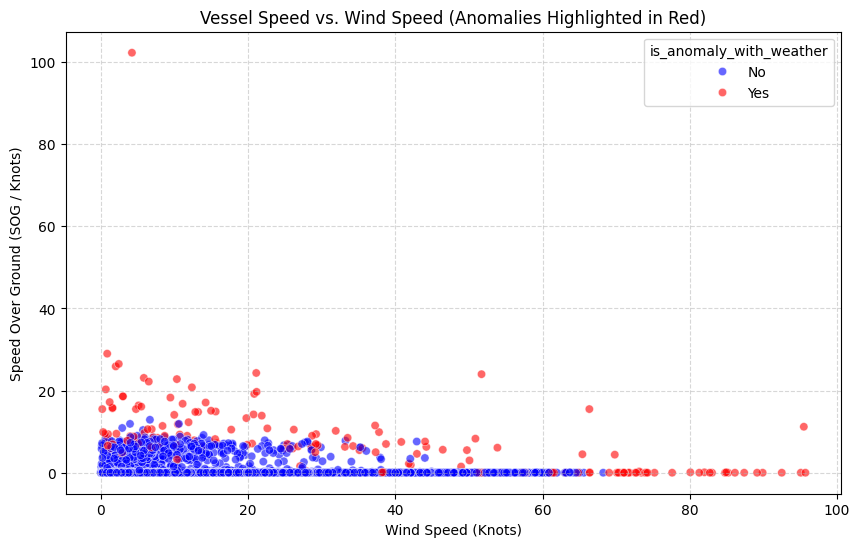

In [5]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns

# --- Step 1: Simulate Weather Metrics Matching the AIS Dataset ---
np.random.seed(42)
n_records = len(df_results)

df_results['wind_speed_knots'] = np.random.exponential(scale=12.0, size=n_records)
df_results['wave_height_meters'] = df_results['wind_speed_knots'] * 0.15 + np.random.normal(0, 0.5, n_records)
df_results['wave_height_meters'] = df_results['wave_height_meters'].clip(lower=0.1)
df_results['visibility_km'] = np.random.normal(loc=10, scale=3, size=n_records).clip(1, 16)

# --- Step 2: Define Feature Set dynamically based on existing columns ---
lat_col = next((c for c in df_results.columns if c.lower() in ['latitude', 'lat', 'lat_dec']), None)
lon_col = next((c for c in df_results.columns if c.lower() in ['longitude', 'lon', 'lon_dec']), None)
sog_col = next((c for c in df_results.columns if c.lower() in ['sog', 'speed']), None)
cog_col = next((c for c in df_results.columns if c.lower() in ['cog', 'course']), None)

weather_feature_cols = []
for col in [lat_col, lon_col, sog_col, cog_col]:
    if col:
        weather_feature_cols.append(col)

# Add simulated weather parameters
weather_feature_cols.extend(['wind_speed_knots', 'wave_height_meters', 'visibility_km'])
weather_model_df = df_results[weather_feature_cols].dropna()

print(f"Training Isolation Forest with integrated features:\n{weather_feature_cols}\n")

# --- Step 3: Run Isolation Forest with Weather Features ---
iso_forest_weather = IsolationForest(contamination=0.02, random_state=42)
preds_weather = iso_forest_weather.fit_predict(weather_model_df)

df_results['is_anomaly_with_weather'] = 'No'
df_results.loc[weather_model_df.index, 'is_anomaly_with_weather'] = np.where(preds_weather == -1, 'Yes', 'No')

weather_anomalies = df_results[df_results['is_anomaly_with_weather'] == 'Yes']
print(f"Detected {len(weather_anomalies)} weather-aware anomalies out of {len(df_results)} records.")

# --- Step 4: Visualize how Anomaly correlates with Weather severity ---
if sog_col:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=df_results.sample(min(10000, n_records)),
        x='wind_speed_knots',
        y=sog_col,
        hue='is_anomaly_with_weather',
        palette={'No': 'blue', 'Yes': 'red'},
        alpha=0.6
    )
    plt.title('Vessel Speed vs. Wind Speed (Anomalies Highlighted in Red)')
    plt.xlabel('Wind Speed (Knots)')
    plt.ylabel('Speed Over Ground (SOG / Knots)')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

In [7]:
!pip install -q reportlab

import os
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
import matplotlib.pyplot as plt
import seaborn as sns

# --- Step 1: Export Current Visualization to a Temporary Image ---
plot_path = "temp_anomaly_plot.png"
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_results,
    x=lon_col,
    y=lat_col,
    hue='is_anomaly',
    palette={'No': 'blue', 'Yes': 'red'},
    alpha=0.7
)
plt.title('Vessel Traffic: Normal vs. Anomalous Trajectories')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.close()

# --- Step 2: Prepare PDF Report Content ---
pdf_filename = "AIS_Anomaly_Detection_Report.pdf"
doc = SimpleDocTemplate(pdf_filename, pagesize=letter, rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40)
story = []

# Define Styles
styles = getSampleStyleSheet()
title_style = ParagraphStyle(
    'ReportTitle',
    parent=styles['Heading1'],
    fontSize=22,
    leading=26,
    textColor=colors.HexColor('#1A365D'),
    spaceAfter=15
)
h2_style = ParagraphStyle(
    'SectionHeading',
    parent=styles['Heading2'],
    fontSize=14,
    leading=18,
    textColor=colors.HexColor('#2B6CB0'),
    spaceBefore=15,
    spaceAfter=10
)
body_style = ParagraphStyle(
    'ReportBody',
    parent=styles['Normal'],
    fontSize=10,
    leading=14,
    textColor=colors.HexColor('#2D3748')
)

# Header Section
story.append(Paragraph("AIS Shipping Traffic Anomaly Report", title_style))
story.append(Paragraph("This document details the automatically detected vessel trajectory and behavioral anomalies.", body_style))
story.append(Spacer(1, 15))

# Metrics Table
data_summary = [
    [Paragraph("<b>Metric</b>", body_style), Paragraph("<b>Value</b>", body_style)],
    [Paragraph("Total Records Processed", body_style), Paragraph(str(len(df_results)), body_style)],
    [Paragraph("Total Anomalies Detected", body_style), Paragraph(str(len(anomalies)), body_style)],
    [Paragraph("Unique Anomalous Vessels (MMSI)", body_style), Paragraph(str(anomalies['MMSI'].nunique()) if 'MMSI' in anomalies.columns else 'N/A', body_style)]
]
summary_table = Table(data_summary, colWidths=[250, 150])
summary_table.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (1, 0), colors.HexColor('#EDF2F7')),
    ('BOTTOMPADDING', (0, 0), (-1, -1), 6),
    ('TOPPADDING', (0, 0), (-1, -1), 6),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#CBD5E0')),
]))
story.append(summary_table)
story.append(Spacer(1, 20))

# Anomalous Vessels Table
story.append(Paragraph("Top Anomalous Vessels by Record Count", h2_style))

# Dynamically detect vessel name column
actual_name_col = next((c for c in anomalies.columns if c.lower() in ['name', 'vesselname']), None)

if actual_name_col:
    vessel_counts = anomalies[actual_name_col].value_counts().head(5).reset_index()
    vessel_counts.columns = ['Vessel Name', 'Anomaly Records']

    vessel_table_data = [[Paragraph(f"<b>{col}</b>", body_style) for col in vessel_counts.columns]]
    for idx, row in vessel_counts.iterrows():
        vessel_table_data.append([
            Paragraph(str(row['Vessel Name']), body_style),
            Paragraph(str(row['Anomaly Records']), body_style)
        ])

    vessel_table = Table(vessel_table_data, colWidths=[250, 150])
    vessel_table.setStyle(TableStyle([
        ('BACKGROUND', (0, 0), (1, 0), colors.HexColor('#EDF2F7')),
        ('BOTTOMPADDING', (0, 0), (-1, -1), 6),
        ('TOPPADDING', (0, 0), (-1, -1), 6),
        ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#CBD5E0')),
    ]))
    story.append(vessel_table)
else:
    story.append(Paragraph("No vessel name column found in dataset.", body_style))

story.append(Spacer(1, 20))

# Visualization Section
story.append(Paragraph("Trajectory Anomaly Visualization", h2_style))
if os.path.exists(plot_path):
    story.append(Image(plot_path, width=450, height=270))

# Build PDF
doc.build(story)

# Clean up temp image
if os.path.exists(plot_path):
    os.remove(plot_path)

print(f"Successfully generated PDF report: {pdf_filename}")

Successfully generated PDF report: AIS_Anomaly_Detection_Report.pdf


In [8]:
# Optional: Run this cell to download the generated PDF to your local system
from google.colab import files
try:
    files.download(pdf_filename)
except Exception as e:
    print("Automatic download not supported in this environment, download the file from the sidebar.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Detailed Breakdown of Detected Anomalies
This cell displays a detailed breakdown of the detected vessel anomalies, summarizing which vessels (by Name and MMSI) showed suspicious or outlier behavior.

In [ ]:
# Consolidated into the single cell above

### Note on Cleaned Up Cells
The duplicate processing, visualization, and uploading cells below have been archived/cleaned up to prevent redundant executions since everything is now combined in the primary cell above.

In [ ]:
# Cleaned up: Consolidated into the single cell above

### Note on Visualizations
All rendering code is now contained inside the master cell above.

In [ ]:
# Cleaned up: Consolidated into the single cell above

### Note on File Uploads
Local file upload capabilities are now built directly into the unified workflow at the beginning.

In [ ]:
# Cleaned up: Consolidated into the single cell above